In [ ]:
from matplotlib import pyplot as plt
import numpy as np
from scipy.special import jv, kv
from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, eta_0, mu_0, pi
import scipy.integrate as integrate


In [2]:
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0

In [3]:
from scipy.optimize import brentq
from scipy.optimize import fminbound
# The Brent's method is a root-finding algorithm that combines the bisection method, the secant method, and 
# inverse quadratic interpolation. 
# https://en.wikipedia.org/wiki/Brent%27s_method
# It is designed to find roots of a continuous function within a specified interval where the function changes
#  sign. The method is efficient and robust, making it suitable for finding roots of nonlinear equations.

In [4]:
from dataclasses import dataclass

In [5]:
# # Given the X and Y roots for the LP01 mode from previous calculations
# X_root = 1.5590595758091075
# Y_root = 1.3985078062014993

def function_LP01(X, V):
    ""
    # Calculate Y based on the relationship Y^2 = V^2 - X^2
    Y = np.sqrt(V**2 - X**2)
    # Calculate the left-hand side and right-hand side of the equation using the Bessel functions
    lhs = X * jv(1, X) / jv(0, X)
    rhs = Y * kv(1, Y) / kv(0, Y)
    return lhs - rhs

def find_root_LP01(V, X_min, X_max):
    # Define a lambda function that takes X as input and uses the previously defined function f with the 
    # fixed V value. This allows us to use this function for root finding.
    function_m1 = lambda X: function_LP01(X, V)

    # NEW: restrict X_max to the first zero of J0 so we stay on the LP01 branch
    X_max = min(X_max, jn_zeros(0, 1)[0] - 1e-8)

    # print(f'X_max restricted to {X_max:.6f} to stay on the LP01 branch')

    X_scan = np.linspace(X_min, X_max, 5000)
    F_scan = function_m1(X_scan) # Evaluate the function at the scan points

    bracket = None

    # We take length of scan - 1 because we are checking pairs of points for sign changes, 
    # -1 means we won't go out of bounds when checking F_scan[i + 1]
    for i in range(len(X_scan) - 1): # Loop through the length-1 of X_scan to find a sign change
        if F_scan[i] * F_scan[i + 1] < 0: # Check for a sign change
            x1 = X_scan[i]
            x2 = X_scan[i + 1]
            f1 = F_scan[i]
            f2 = F_scan[i + 1]

            # Skip non-finite values
            if not np.isfinite(f1) or not np.isfinite(f2):
                continue

            # sign chage detected between x1 and x2, we can use this as a bracket for root finding
            if f1*f2 < 0:
                bracket = (x1, x2) # Store the bracket where the sign change occurs
                break # Exit the loop after finding the first sign change

    if bracket is None:
        raise ValueError(f"No valid bracket found for V = {V:.6f}")

    X_root = brentq(function_m1, bracket[0], bracket[1]) # Use the found bracket for root finding
    Y_root = np.sqrt(V**2 - X_root**2)
    return X_root, Y_root


In [6]:
def calculate_electric_field(r, a, X_root, Y_root):
    """ 
    Define a function to calculate the electric field distribution across the fibre 
    cross-section based on the roots found from the Bessel function equations. This function 
    will compute the electric field in both the core and cladding regions, normalise it, and 
    return both the normalised electric field and its intensity profile. 

    X_root: The root of the equation for the core region, which determines the behaviour of the electric field within the core.
    Y_root: The root of the equation for the cladding region, which determines the behaviour of the electric field in the cladding.
    rho: The normalised radius array (r/a) across which we want to calculate the electric field distribution.

    """
    # Step 1 - Convert radial coordinate to normalised distance

    rho = r / a

    # Step 2 - Create an array of zeros with the same shape as rho to store the electric field values
    E = np.zeros_like(rho)

    # Step 3 - Set the condition as the boundary between core and cladding, this helps to create a piecewise function for the electric field distribution
    core = rho <= 1
    cladding = rho > 1

    # Step 4 - Compute the electric field in the core region (rho <= 1) using the ordinary Bessel function J0.
    # E[core] uses conditional (boolean) assignment directly: values are assigned only where the condition is satisfied, allowing us to implement the piecewise solution of the wave equation without using loops.
    # Physically, this corresponds to applying the core solution E(rho) = J0(X*rho) only inside the fibre core.

    E[core] = jv(0, X_root * rho[core]) # Setting A = 1, multiplied by te Bessel function of zeroth order and ratio rho inside the core

    # Step 5 - Set the matching factor at the boundary (rho=1) as J0(X) / K0(Y), this makes the cladding field connect smoothly
    match_factor = jv(0,X_root) / kv(0,Y_root) 

    # Step 6 - Compute the electric field in the cladding region (rho > 1) using the modified Bessel function K0, multiplied by the matching factor to ensure continuity at the boundary
    E[cladding] = match_factor * kv(0, Y_root * rho[cladding])

    # Step 7 - Normalise the electric field distribution so that the maximum value is 1, this allows us to compare the relative field strength across the fibre cross-section
    E_norm = E / np.max(abs(E)) 

    # Step 8 - We also compute the intensity profile of the electric field, such that I represents the intensity profile and E represents the field amplitude. 
    I = np.abs(E_norm)**2

    return E_norm, I # note they are in normalised units

In [7]:
def coude_diffraction_limited_E_field(r, lam0, F_focus, alpha, E_S):

    """
    Function for calculating the E-field at diffraction limited E_field, specifically for
    the Coude focus (or a focus that has a long focal length resulting in high magnification)

    r: radial coordinate in the image plane (in meters)
    lam0: wavelength of the incoming beam in vacuum (in meters)
    F: focal ratio (f/#) of the telescope, defined as the focal length divided by the diameter of the primary mirror
    alpha: ratio of the central obstruction diameter to the primary mirror diameter, which affects the diffraction pattern and thus the E-field distribution at the focus
    E_S: amplitude of the incoming E-field, which can be set to 1 for normalisation purposes
    """

    s = np.pi * r / (lam0 * F) # Normalised radial coordinate for the diffraction pattern

    # Use safe division so the s=0 limit is finite (2*J1(x)/x -> 1 as x->0)
    airy_term = np.divide(2 * j1(s), s, out=np.ones_like(s), where=s != 0)
    obstruction_term = np.divide(2 * j1(alpha * s), alpha * s, out=np.ones_like(s), where=(alpha * s) != 0)

    # The electric field of image found from the diffraction pattern of the telescope aperture, modified by the 
    # central obstruction, multiplied by the fibre mode field distribution to get the resulting image field 
    # distribution at the fibre input. Note: zero division at centre is artificially set to 1 
    E_image = E_S * (airy_term - alpha**2 * obstruction_term)

    # Intensity of the incoming beam forming an image at the fibre input 
    I_image = np.abs(E_image)**2

    return E_image, I_image

In [8]:
# def demagnified_diffraction_limited_E_field(r, lam0, F_focus, alpha, E_S, Magnification):
#     """
#     r: the radius array created, representing distance vector in the ribre radius
    
#     lam0: wavelength of the light in air

#     F_focus: focal ratio F=f/D at the focus

#     alpha: the ratio of central obstration to primary mirror diameter

#     E_S: amplitude of the E-field of image normalised (assumed) to equal to 1 here

#     Magnification: different to the magnification measurement between image at the telescope 
#     and focus, the Magnification here refers to the required scale of "magnification" or inverted 
#     demagnification required for the re-imaging optics

#     """

#     s_demag = np.pi * r / (lam0 * F_focus * Magnification) # Normalised radial coordinate for the diffraction pattern after demagnification

#     # Use safe division so the s=0 sample does not produce NaN
#     airy_term_demag = np.divide(2 * j1(s_demag), s_demag, out=np.ones_like(s_demag), where=s_demag != 0)
#     obstruction_term_demag = np.divide(2 * j1(alpha * s_demag), alpha * s_demag,
#         out=np.ones_like(s_demag),
#         where=(alpha * s_demag) != 0,
#     )

#     # The electric field of image found from the diffraction pattern of the telescope aperture, modified by the 
#     # central obstruction, multiplied by the fibre mode field distribution to get the resulting image field distribution at the fibre input.
#     E_image_demag = E_S * (airy_term_demag - alpha**2 * obstruction_term_demag)

#     # Intensity of the incoming beam forming an image at the fibre input 
#     I_image_demag = np.abs(E_image_demag)**2

#     return E_image_demag, I_image_demag

In [9]:
def diffraction_limited_E_field_at_fibre(r, lam0, F_eff, alpha=0.0, E_S=1.0):
    """
    Diffraction-limited telescope image electric field evaluated
    at the fibre input plane.

    Parameters
    ----------
    r : array
        Radial coordinate in the fibre input plane [m]
    lam0 : float
        Wavelength [m]
    F_eff : float
        Effective focal ratio at the fibre input plane
    alpha : float
        Central obstruction ratio
    E_S : float
        Overall field amplitude

    Returns
    -------
    E_image : array
        Electric field at the fibre input plane
    I_image : array
        Intensity at the fibre input plane
    """

    s = np.pi * r / (lam0 * F_eff)

    airy_term = np.divide(
        2 * j1(s),
        s,
        out=np.ones_like(s),
        where=s != 0
    )

    if alpha > 0:
        obstruction_term = np.divide(
            2 * j1(alpha * s),
            alpha * s,
            out=np.ones_like(s),
            where=(alpha * s) != 0
        )
        E_image = E_S * (airy_term - alpha**2 * obstruction_term)
    else:
        E_image = E_S * airy_term

    I_image = np.abs(E_image)**2
    return E_image, I_image

In [ ]:
# The entire radial range
def coupling_efficiency_1d(E_image_demag, E_smf, r):
    """
    Input: 
    E_image_demag: electric field of demagnified image
    E_smf: electric field of single mode fibre

    Output: 
    numerator = |∫ E_image_demag * conj(E_smf) * 2πr dr|^2
    denominator = ∫ |E_smf|^2 * 2πr dr * ∫ |E_image_demag|^2 * 2πr dr
    efficiency eta: we integrate from infinitely large radius to the centre (but here 
    instead of infinity we use the finite range of r that we have where largest r must be larger
    than cladding radius to capture the Evanescent field distribution)
    
    """
    numerator = np.abs(np.trapezoid(E_image_demag * np.conjugate(E_smf) * 2*np.pi*r, x=r))**2
    denominator = np.trapezoid(np.abs(E_smf)**2 * 2*np.pi*r, x=r) * np.trapezoid(np.abs(E_image_demag)**2 * 2*np.pi*r, x=r)
    # Calculate efficiency:
    eta = numerator / denominator

    return eta, numerator, denominator

In [11]:
# wavelength of beam in vacuum
lam0 = 1.5e-6 
# fibre core radius
a = 5e-6 
# numerical aperture of fibre
NA = 0.1 

# Calculate the normalised frequency (V-number) of the fibre
V = 2 * pi * (a / lam0) * NA
print(f"V-number of the fibre: {V:.2f}")

V-number of the fibre: 2.09


In [12]:
# Approximate number of modes that the fibre can support using the V-number
M = V**2 / 4
print(f"Approximate number of modes that the fibre can support: {M:.2f}")

Approximate number of modes that the fibre can support: 1.10


## Radial Power Distibution
Let's use an alternative coupling efficiency method to that uses radial power distribution, to verify with the coupling efficiency calculated from the overlap integral method. This method is based on the fact that 
the coupling efficiency is proportional to the fraction of the fibre mode power that falls within the fibre core radius. 

In [ ]:
# # Radial power distribution method, but now weighted by the SMF mode intensity.
# # This is still an approximation, but it is more SMF-like than a hard core cutoff.

# def eta_radial_power_method(I_image, E_smf, r):
#     """
#     Approximate SMF-like coupling proxy using image intensity weighted
#     by the fibre mode intensity.

#     Parameters
#     ----------
#     I_image : array
#         Image intensity profile evaluated on radius grid r
#     E_smf : array
#         SMF electric field evaluated on the same radius grid
#     r : array
#         Physical radius array [m]

#     Returns
#     -------
#     eta_radial : float
#         Mode-weighted radial power proxy
#     numerator : float
#         Weighted image power
#     denominator : float
#         Product of total image power and total mode power
#     """
#     I_mode = np.abs(E_smf)**2

#     numerator = np.trapezoid(
#         I_image * I_mode * 2*np.pi*r,
#         x=r
#     )

#     denominator = (
#         np.trapezoid(I_image * 2*np.pi*r, x=r)
#         *
#         np.trapezoid(I_mode * 2*np.pi*r, x=r)
#     )

#     eta_radial = numerator / denominator

#     return eta_radial, numerator, denominator

In [ ]:
# def efficiency_vs_core_radius_radial_power_method(core_radius_range_test, cladding_radius_max,
#                                                   lam0, NA, F_focus, alpha, E_S, Magnification): 
    

#     efficiency_signal_test_radial = np.zeros_like(core_radius_range_test, dtype=float)
#     efficiency_noise_test_radial = np.zeros_like(core_radius_range_test, dtype=float)

#     numerator_signal_test_radial = np.zeros_like(core_radius_range_test, dtype=float)
#     denominator_signal_test_radial = np.zeros_like(core_radius_range_test, dtype=float)

#     numerator_noise_test_radial = np.zeros_like(core_radius_range_test, dtype=float)
#     denominator_noise_test_radial = np.zeros_like(core_radius_range_test, dtype=float)

#     V_norm_radial = np.zeros_like(core_radius_range_test, dtype=float)

#     for i, a in enumerate(core_radius_range_test):

#         V = 2 * np.pi * (a / lam0) * NA
#         X_min = 0 + 1e-8
#         X_max = V - 1e-8

#         X_root, Y_root = find_root_LP01(V, X_min, X_max)

#         fibre_rho = np.linspace(0, cladding_radius_max / a, 1000)
#         fibre_r = fibre_rho * a

#         E_smf, I_smf = calculate_electric_field(fibre_rho, X_root, Y_root)

#         E_image, I_image = demagnified_diffraction_limited_E_field(
#             fibre_r, lam0, F_focus, alpha, E_S, Magnification
#         )

#         E_flat = np.ones_like(fibre_r)
#         I_flat = np.abs(E_flat)**2

#         eta_signal, numerator_signal, denominator_signal = eta_radial_power_method(
#             I_image, E_smf, fibre_r
#         )
#         eta_noise, numerator_noise, denominator_noise = eta_radial_power_method(
#             I_flat, E_smf, fibre_r
#         )

#         efficiency_signal_test_radial[i] = eta_signal
#         efficiency_noise_test_radial[i] = eta_noise

#         numerator_signal_test_radial[i] = numerator_signal
#         denominator_signal_test_radial[i] = denominator_signal

#         numerator_noise_test_radial[i] = numerator_noise
#         denominator_noise_test_radial[i] = denominator_noise

#         V_norm_radial[i] = V

#     return (
#         efficiency_signal_test_radial,
#         efficiency_noise_test_radial,
#         numerator_signal_test_radial,
#         denominator_signal_test_radial,
#         numerator_noise_test_radial,
#         denominator_noise_test_radial,
#         V_norm_radial
#     )

In [15]:
# core_radius_range_test = np.linspace(1.2e-6, 50e-6, 1000) # from 4 to 20 microns in meters
# # The cladding radius should be set to 125/2 micron
# cladding_radius_max = 1250e-6 / 2

# efficiency_signal_test = np.zeros_like(core_radius_range_test)
# efficiency_noise_test = np.zeros_like(core_radius_range_test)
# numerator_signal_test = np.zeros_like(core_radius_range_test)
# denominator_signal_test = np.zeros_like(core_radius_range_test)
# numerator_noise_test = np.zeros_like(core_radius_range_test)
# denominator_noise_test = np.zeros_like(core_radius_range_test)

# V_norm = np.zeros_like(core_radius_range_test)

In [16]:
# F_focus = 49.9
# NA = 0.1
# alpha = 0
# E_S = 1.0

# F_fibre = 1 / (2 * np.tan(np.arcsin(NA)))

# # Radius of airy disk at the first minimum after demagnification
# r_airy = 1.22 * lam0 * F_focus
# print(f"Radius of airy disk at the first minimum: {r_airy} meters")

# Magnification = F_fibre / F_focus
# r_airy_demag = (1.22*lam0 * F_focus) * Magnification

# print(f"Radius of airy disk at the first minimum after demagnification: {r_airy_demag} meters")
# print(f"Magnification factor: {Magnification:.9f}")

In [17]:
# efficiency_signal_test_radial, efficiency_noise_test_radial, numerator_signal_test_radial, denominator_signal_test_radial, numerator_noise_test_radial, denominator_noise_test_radial, V_norm_radial = efficiency_vs_core_radius_radial_power_method(
#     core_radius_range_test, cladding_radius_max, lam0, NA, F_focus, alpha, E_S, Magnification
# )

In [18]:
# plt.figure(figsize=(12,6))
# plt.plot(core_radius_range_test * 1e6, efficiency_signal_test_radial,
#          label='Radial Power Efficiency (Signal)', color='blue')

# index_signal_test_radial = np.argmax(efficiency_signal_test_radial)

# plt.scatter(core_radius_range_test[index_signal_test_radial] * 1e6,
#             efficiency_signal_test_radial[index_signal_test_radial],
#             color='red', marker='x',
#             label=f'Max Radial Power Efficiency: {efficiency_signal_test_radial[index_signal_test_radial]:.4f} at a={core_radius_range_test[index_signal_test_radial]*1e6:.2f} µm')

# # Optional:
# # plt.plot(core_radius_range_test * 1e6, efficiency_noise_test_radial,
# #          label='Radial Power Efficiency (Flat Field)', color='red')

# plt.xlabel('Core radius (µm)')
# plt.ylabel('Efficiency')
# plt.legend()
# plt.grid(True)
# plt.show()

In [19]:
# plt.figure(figsize=(12,6))
# plt.plot(core_radius_range_test * 1e6, efficiency_noise_test_radial,
#          label='Radial Power Efficiency (Flat Field)', color='red')

# index_noise_test_radial = np.argmax(efficiency_noise_test_radial)

# plt.scatter(core_radius_range_test[index_noise_test_radial] * 1e6,
#             efficiency_noise_test_radial[index_noise_test_radial],
#             color='red', marker='x',
#             label=f'Max Radial Power Efficiency: {efficiency_noise_test_radial[index_noise_test_radial]:.4f} at a={core_radius_range_test[index_noise_test_radial]*1e6:.2f} µm')

# # Optional:
# # plt.plot(core_radius_range_test * 1e6, efficiency_noise_test_radial,
# #          label='Radial Power Efficiency (Flat Field)', color='red')

# plt.xlabel('Core radius (µm)')
# plt.ylabel('Efficiency')
# plt.legend()
# plt.grid(True)
# plt.show()

## Calculate Maximum Efficiency via Optimal Focal Ratio at the fibre radius

In [20]:
F_focus = 49.9
NA = 0.1
alpha = 0
E_S = 1.0

F_fibre = 1 / (2 * np.tan(np.arcsin(NA)))

# Radius of airy disk at the first minimum after demagnification
# r_airy = 1.22 * lam0 * F_focus
print(f"Radius of airy disk at the first minimum: {r_airy} meters")

# Magnification = F_fibre / F_focus
# r_airy_demag = (1.22*lam0 * F_focus) * Magnification

# print(f"Radius of airy disk at the first minimum after demagnification: {r_airy_demag} meters")
# print(f"Magnification factor: {Magnification:.9f}")

NameError: name 'r_airy' is not defined

In [ ]:
# fminbound?

In [ ]:
np.arange(0.1,0.5 + 0.1,0.1)

array([0.1, 0.2, 0.3, 0.4, 0.5])

In [ ]:
print(np.arange(2.5e-6, 30e-6, 0.5e-6).shape)


(56,)


In [ ]:
print(np.arange(2.5e-6, 30e-6 + 0.5e-6, 0.5e-6).shape)

(56,)


In [ ]:
core_radius_range_test = np.arange(2.5e-6, 30e-6 + 0.5e-6, 0.05e-6) # from 2 to 50 microns in meters, note arange is exclusive of the endpoint, so we add 0.5e-6 to include 30e-6 in the range
core_radius_range_test

array([2.500e-06, 2.550e-06, 2.600e-06, 2.650e-06, 2.700e-06, 2.750e-06,
       2.800e-06, 2.850e-06, 2.900e-06, 2.950e-06, 3.000e-06, 3.050e-06,
       3.100e-06, 3.150e-06, 3.200e-06, 3.250e-06, 3.300e-06, 3.350e-06,
       3.400e-06, 3.450e-06, 3.500e-06, 3.550e-06, 3.600e-06, 3.650e-06,
       3.700e-06, 3.750e-06, 3.800e-06, 3.850e-06, 3.900e-06, 3.950e-06,
       4.000e-06, 4.050e-06, 4.100e-06, 4.150e-06, 4.200e-06, 4.250e-06,
       4.300e-06, 4.350e-06, 4.400e-06, 4.450e-06, 4.500e-06, 4.550e-06,
       4.600e-06, 4.650e-06, 4.700e-06, 4.750e-06, 4.800e-06, 4.850e-06,
       4.900e-06, 4.950e-06, 5.000e-06, 5.050e-06, 5.100e-06, 5.150e-06,
       5.200e-06, 5.250e-06, 5.300e-06, 5.350e-06, 5.400e-06, 5.450e-06,
       5.500e-06, 5.550e-06, 5.600e-06, 5.650e-06, 5.700e-06, 5.750e-06,
       5.800e-06, 5.850e-06, 5.900e-06, 5.950e-06, 6.000e-06, 6.050e-06,
       6.100e-06, 6.150e-06, 6.200e-06, 6.250e-06, 6.300e-06, 6.350e-06,
       6.400e-06, 6.450e-06, 6.500e-06, 6.550e-06, 

In [ ]:
def make_E_image_demag_(r, lam0, F_focus, alpha, E_S):
    """
    r: the radius array created, representing distance vector in the ribre radius
    
    lam0: wavelength of the light in air

    F_focus: focal ratio F=f/D at the focus

    alpha: the ratio of central obstration to primary mirror diameter

    E_S: amplitude of the E-field of image normalised (assumed) to equal to 1 here

    Magnification: different to the magnification measurement between image at the telescope 
    and focus, the Magnification here refers to the required scale of "magnification" or inverted 
    demagnification required for the re-imaging optics

    """

    s_demag = np.pi * r / (lam0 * F_focus * Magnification) # Normalised radial coordinate for the diffraction pattern after demagnification

    # Use safe division so the s=0 sample does not produce NaN
    airy_term_demag = np.divide(2 * j1(s_demag), s_demag, out=np.ones_like(s_demag), where=s_demag != 0)
    obstruction_term_demag = np.divide(2 * j1(alpha * s_demag), alpha * s_demag,
        out=np.ones_like(s_demag),
        where=(alpha * s_demag) != 0,
    )

    # The electric field of image found from the diffraction pattern of the telescope aperture, modified by the 
    # central obstruction, multiplied by the fibre mode field distribution to get the resulting image field distribution at the fibre input.
    E_image_demag = E_S * (airy_term_demag - alpha**2 * obstruction_term_demag)

    # Intensity of the incoming beam forming an image at the fibre input 
    I_image_demag = np.abs(E_image_demag)**2

    return E_image_demag, I_image_demag

In [ ]:
def maximize_coupling_fixed_radius(r, a, lam0, NA, E_mode, alpha=0.0, E_S=1.0):
    """
    Nested Function to maximise coupling efficiency for a fixed core radius by optimising the magnification factor of the re-imaging optics. 
    This allows us to find the optimal magnification that maximises coupling efficiency for a given fibre core radius, which is crucial 
    for designing the re-imaging optics in a way that maximises the coupling of light into the single-mode fibre.

    The key to this function is the **fminbound** source code, it has a loop embeded, it will call the objective function multiple times with different F_eff values to 
    find the minimum of the objective function, which corresponds to the maximum coupling efficiency.
    """

    F_eff_guess = 1 / (2 * np.tan(np.arcsin(NA)))

    lower = F_eff_guess * 0.2
    upper = F_eff_guess * 5.0

    # Step 2 - Define a optimisation function that takes the effective focal ratio F_eff as input and returns 1 - coupling efficiency, so 
    # that we can use a minimisation function to find the F_eff that maximises coupling efficiency

    def objective(F_eff):
        "Input the tested focal ratio F, and return 1 - coupling efficiency for the given fibre focal ratio F_eff, so that we can use a minimisation function "
        "to find the F/# that maximises coupling efficiency"

        E_image_demag, I_image_demag = diffraction_limited_E_field_at_fibre(r, lam0, F_eff, alpha=0.0, E_S=1.0)
        
        eta,_,_ = coupling_efficiency_1d(E_image_demag, E_mode, r)
        return 1 - eta
    
    
    # Step 3 - Use a bounded minimisation function to find the optimal F_eff that maximises coupling efficiency, we set the bounds to be 
    # between 1 and 30, which is a reasonable range for focal ratio at the fibre input. 
    
    # objective works as a closure that evaluates 1 - eta for any given F_eff, and fminbound will find the F_eff that minimises this objective, which corresponds to maximising eta.
    F_opt = fminbound(objective, lower, upper) # When fminbound internally calls objective(some_number), the nested function already knows what r and lam0 
    # are without fminbound ever having to know they exist. 

    # Sample the efficiency curve for plotting
    F_grid = np.linspace(lower, upper, 200)
    eta_grid = np.array([1 - objective(F) for F in F_grid])

    # Step 4 - Compute the electric field and intensity of the image at the fibre input using the optimal F_eff
    E_image_demag_opt, I_image_demag_opt = diffraction_limited_E_field_at_fibre(r, lam0, F_opt, alpha=0.0, E_S=1.0)

    # Step 5 - Calculate the coupling efficiency using the optimal F_eff
    eta_best, numerator, denominator = coupling_efficiency_1d(E_image_demag_opt, E_mode, r)

    return F_opt, eta_best, numerator, denominator, F_grid, eta_grid






In [ ]:
@dataclass
class CouplingResult:
    a: float
    V: float
    E_smf: np.ndarray
    F_opt: float
    eta_best: float
    F_grid: np.ndarray
    eta_grid: np.ndarray

def sweep_core_radius_and_optimize_F_lp01(core_radius_range_test, r, lam0, NA, alpha=0.0, E_S=1.0): 
    
    """
    This function loops through the core radius range, calculates the electric field distribution for each core radius, 
    and then optimises the focal ratio of the re-imaging optics to maximise coupling efficiency for each core radius. 
    The results are stored in a list of CouplingResult dataclass instances, which contain the core radius, V-number, 
    electric field distribution, optimal focal ratio, best coupling efficiency, and the grid of focal ratios and corresponding efficiencies for plotting. 
    This allows us to analyse how the optimal focal ratio and coupling efficiency vary with core radius, which is crucial for designing the fibre and re-imaging optics system.
    """

    results = []

    for i, a in enumerate(core_radius_range_test): 
        # Step A - Calculate the V-number for the current core radius
        V = 2 * np.pi * (a /lam0) * NA

        X_root, Y_root = find_root_LP01(V, X_min=0, X_max=V)

        E_smf, I_smf = calculate_electric_field(r, a, X_root, Y_root) 

        # Compute the maximum coupling efficiency for the current core radius by optimising the focal ratio of the re-imaging optics
        F_opt, eta_best, numerator, denominator, F_grid, eta_grid = maximize_coupling_fixed_radius(
    r, a, lam0, NA, E_smf, alpha, E_S
)

        results.append(
            CouplingResult(
                a=a,
                V=V,
                E_smf=E_smf,
                F_opt=F_opt,
                eta_best=eta_best,
                F_grid=F_grid,
                eta_grid=eta_grid
            )
        )

    return results



In [ ]:
r = np.linspace(0, 125e-6, 1000) # from 0 to 125 microns in meters, this should cover the entire fibre cross-section including the cladding
results = sweep_core_radius_and_optimize_F_lp01(core_radius_range_test, r, lam0, NA, alpha=0.0, E_S=1.0)
results

/var/folders/pk/ftg5vwzs3r1dhbzyhbqk09580000gp/T/ipykernel_11169/2748491495.py:11: RuntimeWarning: invalid value encountered in multiply
  rhs = Y * kv(1, Y) / kv(0, Y)


[CouplingResult(a=np.float64(2.5e-06), V=np.float64(1.0471975511965979), E_smf=array([1.00000000e+00, 9.99350549e-01, 9.97403463e-01, 9.94162534e-01,
        9.89634076e-01, 9.83826907e-01, 9.76752332e-01, 9.68424121e-01,
        9.58858475e-01, 9.48073991e-01, 9.36091625e-01, 9.22934647e-01,
        9.08628585e-01, 8.93201177e-01, 8.76682305e-01, 8.59103935e-01,
        8.40500046e-01, 8.20906557e-01, 8.00361250e-01, 7.78903687e-01,
        7.56575543e-01, 7.34471515e-01, 7.13502747e-01, 6.93570083e-01,
        6.74586920e-01, 6.56477161e-01, 6.39173571e-01, 6.22616447e-01,
        6.06752522e-01, 5.91534068e-01, 5.76918146e-01, 5.62865982e-01,
        5.49342442e-01, 5.36315582e-01, 5.23756274e-01, 5.11637880e-01,
        4.99935973e-01, 4.88628095e-01, 4.77693552e-01, 4.67113230e-01,
        4.56869435e-01, 4.46945757e-01, 4.37326947e-01, 4.27998805e-01,
        4.18948090e-01, 4.10162432e-01, 4.01630256e-01, 3.93340714e-01,
        3.85283627e-01, 3.77449429e-01, 3.69829116e-01, 3.

In [ ]:
for res in results: 
    print(f"Core radius: {res.a*1e6:.2f} µm, V-number: {res.V:.2f}, Optimal F_eff: {res.F_opt:.2f}, Max Coupling Efficiency: {res.eta_best:.4f}")

Core radius: 2.50 µm, V-number: 1.05, Optimal F_eff: 11.26, Max Coupling Efficiency: 0.6902
Core radius: 2.55 µm, V-number: 1.07, Optimal F_eff: 10.97, Max Coupling Efficiency: 0.6917
Core radius: 2.60 µm, V-number: 1.09, Optimal F_eff: 10.10, Max Coupling Efficiency: 0.6930
Core radius: 2.65 µm, V-number: 1.11, Optimal F_eff: 9.83, Max Coupling Efficiency: 0.6953
Core radius: 2.70 µm, V-number: 1.13, Optimal F_eff: 9.60, Max Coupling Efficiency: 0.6969
Core radius: 2.75 µm, V-number: 1.15, Optimal F_eff: 8.94, Max Coupling Efficiency: 0.6990
Core radius: 2.80 µm, V-number: 1.17, Optimal F_eff: 8.76, Max Coupling Efficiency: 0.7014
Core radius: 2.85 µm, V-number: 1.19, Optimal F_eff: 8.59, Max Coupling Efficiency: 0.7033
Core radius: 2.90 µm, V-number: 1.21, Optimal F_eff: 8.09, Max Coupling Efficiency: 0.7056
Core radius: 2.95 µm, V-number: 1.24, Optimal F_eff: 7.95, Max Coupling Efficiency: 0.7081
Core radius: 3.00 µm, V-number: 1.26, Optimal F_eff: 7.84, Max Coupling Efficiency: 0.7

In [ ]:
F_opt_arr = np.array([res.F_opt for res in results])
eta_best_arr = np.array([res.eta_best for res in results])


In [ ]:
res.F_opt

np.float64(19.058706519939335)

In [ ]:
F_opt_arr

array([11.26323628, 10.96658347, 10.09930364,  9.82711726,  9.60073407,
        8.94000877,  8.76470556,  8.59421086,  8.08969087,  7.95493162,
        7.83985739,  7.50465431,  7.32785834,  7.24264592,  7.16156931,
        7.02933906,  6.77496832,  6.70722403,  6.65377654,  6.60149363,
        6.53737282,  6.35335747,  6.27002115,  6.22726026,  6.19410728,
        6.16501346,  6.13754268,  6.10994489,  6.08011068,  6.04377436,
        5.98408856,  5.89931976,  5.86231888,  5.83958763,  5.82285103,
        5.80959575,  5.79871559,  5.7896365 ,  5.78200763,  5.77561678,
        5.77031154,  5.76598833,  5.76257118,  5.75999766,  5.75822062,
        5.75719715,  5.75689029,  5.75726762,  5.75829794,  5.75995466,
        5.76221353,  5.76505365,  5.76845926,  5.77242024,  5.77692979,
        5.78199338,  5.78762562,  5.79384453,  5.80069469,  5.80823524,
        5.81654809,  5.82575735,  5.836042  ,  5.84766744,  5.8610312 ,
        5.87676356,  5.89585484,  5.91968383,  5.94882656,  5.97

Text(0.5, 1.0, 'Optimal F_eff vs Core Radius')

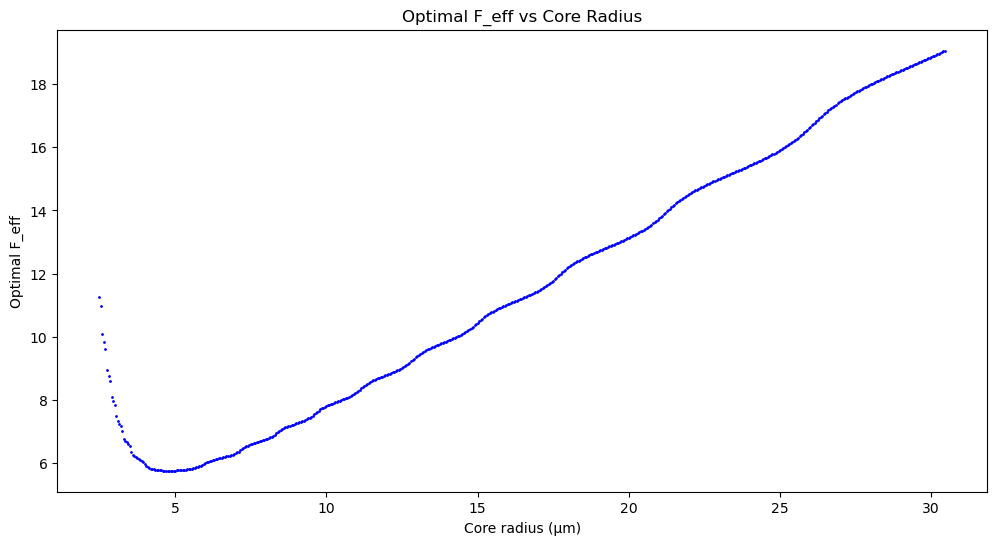

In [ ]:
plt.figure(figsize=(12,6))
plt.scatter(core_radius_range_test * 1e6, F_opt_arr, label='Optimal F_eff for Max Coupling', color='blue', s=1)
plt.xlabel('Core radius (µm)')
plt.ylabel('Optimal F_eff')
plt.title('Optimal F_eff vs Core Radius')

Text(0.5, 1.0, 'Max Coupling Efficiency vs Core Radius')

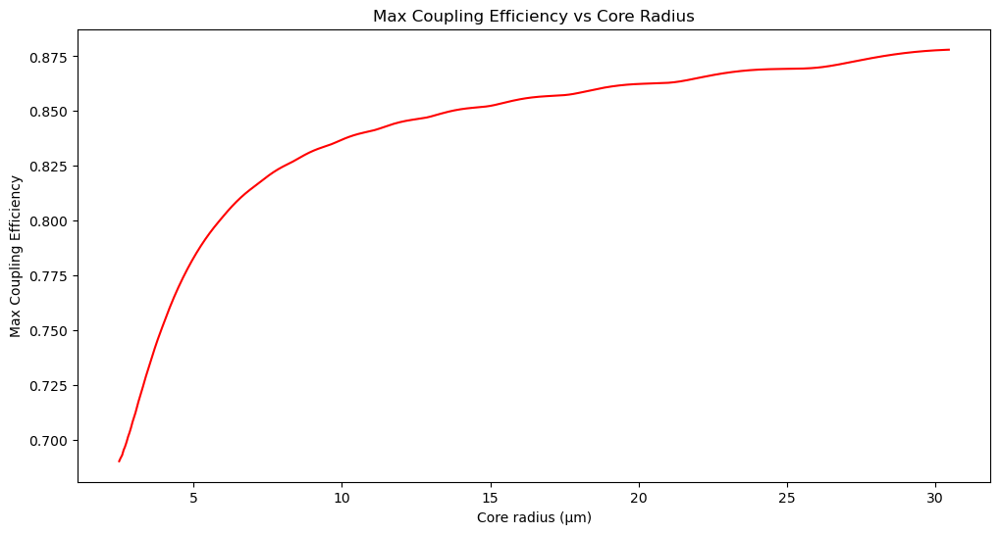

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(core_radius_range_test * 1e6, eta_best_arr, label='Max Coupling Efficiency', color='red')
plt.xlabel('Core radius (µm)')
plt.ylabel('Max Coupling Efficiency')
plt.title('Max Coupling Efficiency vs Core Radius')

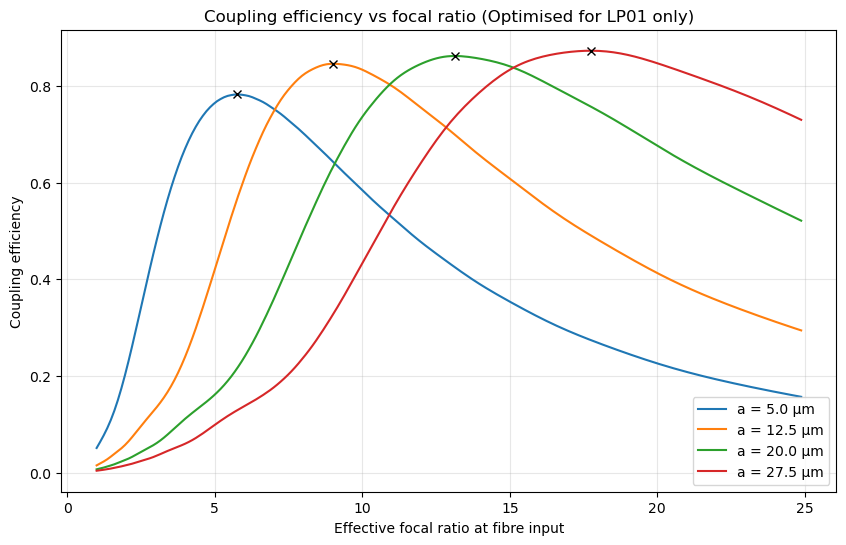

In [ ]:
target_radii_um = [5, 12.5, 20, 27.5]

plt.figure(figsize=(10, 6))

for res in results:
    a_um = res.a * 1e6
    if np.isclose(a_um, target_radii_um, atol=1e-6).any():
        plt.plot(res.F_grid, res.eta_grid, label=f"a = {a_um:.1f} µm")
        plt.plot(res.F_opt, res.eta_best, "x", color="k")

plt.xlabel("Effective focal ratio at fibre input")
plt.ylabel("Coupling efficiency")
plt.title("Coupling efficiency vs focal ratio (Optimised for LP01 only)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# The intensity and electric field would be nearly uniform for the background when 
# pointing to a patch of sky
E_uniform = np.ones_like(r) * 1
I_uniform = np.abs(E_uniform) **2

In [ ]:
# Define the diffraction limited E-field

# Not sure how big the obstruction is, assume it's 11.1 meters in diameter 
D_M1 = 8.0 # Diameter of the primary mirror in meters
D_obstruction = 1.0 # Diameter of the central obstruction in meters
# alpha = D_obstruction / D_M1 # Ratio of the central obstruction to the primary mirror diameter

alpha = 0

# Assume E_S = 1m exactly for the amplitude of the E-field
E_S = 1

In [ ]:
import numpy as np
from scipy import integrate

# Assumed already defined:
# results
# lam0, NA, alpha, E_S
# F_focus, D_M1, Magnification
# cladding_radius_max
# calculate_electric_field
# diffraction_limited_E_field_at_fibre OR make_E_image_demag_
# find_root_LP01

cladding_radius_max = 125e-6

I_flat = 1.0**2   # flat background intensity in normalized units

rad_to_arcsec = (180 / np.pi) * 3600

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1)          # arcsec / metre at telescope focal plane
# plate_scale_demag = plate_scale_coude / Magnification         # arcsec / metre at fibre input plane

# Core radii and optimal focal ratios from your LP01 optimization results
core_radius_arr = np.array([res.a for res in results])
F_opt_arr = np.array([res.F_opt for res in results])

# Scalar outputs
V_array = np.zeros_like(core_radius_arr)
FOV_array = np.zeros_like(core_radius_arr)
signal_array = np.zeros_like(core_radius_arr)
background_array = np.zeros_like(core_radius_arr)
snr_array = np.zeros_like(core_radius_arr)
eta_max_array = np.zeros_like(core_radius_arr)

# Profile outputs: one array per core radius
E_smf_list = []
I_smf_list = []
E_image_list = []
I_image_list = []
r_list = []
eta_background_list = []

Magnification_list = []

for i, a in enumerate(core_radius_arr):

    # Step 1 - fibre V number
    V = 2 * np.pi * (a / lam0) * NA
    V_array[i] = V

    # Step 2 - LP01 roots
    X_min = 0 + 1e-8
    X_max = V - 1e-8
    X_root, Y_root = find_root_LP01(V, X_min, X_max)

    # Step 3 - radial grid for this fibre
    fibre_r = np.linspace(0, cladding_radius_max, 10000)
    fibre_rho = fibre_r / a

    # Step 4 - fibre mode field
    E_smf, I_smf = calculate_electric_field(fibre_r, a, X_root, Y_root)

    # Step 5 - image field at the optimal focal ratio for this core radius
    F_opt = F_opt_arr[i]

    Magnification = F_opt / F_focus 
    plate_scale_demag = plate_scale_coude / Magnification

    E_image, I_image = diffraction_limited_E_field_at_fibre(
        fibre_r, lam0, F_opt, alpha=alpha, E_S=E_S
    )

    # If instead you want to use your demagnified field function, replace Step 5 with:
    # E_image, I_image = make_E_image_demag_(fibre_r, lam0, F_focus=F_opt, alpha=alpha, E_S=E_S)

    # Step 6 - maximum LP01 coupling efficiency at this radius
    eta_max, numerator, denominator = coupling_efficiency_1d(E_image, E_smf, r=fibre_r)
    eta_max_array[i] = eta_max

    # Step 7 - geometric fibre field of view
    FOV = plate_scale_demag * 2 * a     # arcsec
    FOV_array[i] = FOV

    # Step 8 - signal and background terms
    # This follows your earlier definition: signal = total image intensity over fibre plane
    Signal = 2 * np.pi * integrate.simpson(I_image * fibre_r, x=fibre_r)

    # Background from a flat surface brightness over circular FOV
    Background = np.pi * I_flat * (FOV / 2)**2
    # This is the coupling efficiency for the background, which is a flat field, we can calculate it by integrating the product of eta_max 
    # and I_flat over the fibre area, and then normalising by the integral of I_flat over the fibre area. Note that eta_max is a function of radius, 
    # so we need to integrate it over the fibre area to get the effective coupling efficiency for the background.
    eta_background = np.divide(
        integrate.simpson(eta_max * I_flat * 2*np.pi * fibre_r, x=fibre_r),
        integrate.simpson(I_flat * 2*np.pi * fibre_r, x=fibre_r)
    )
    

    # Relative S/N
    snr = Signal / np.sqrt(Background)

    signal_array[i] = Signal
    background_array[i] = Background
    snr_array[i] = snr

    # Step 9 - store full profiles
    E_smf_list.append(E_smf)
    I_smf_list.append(I_smf)
    E_image_list.append(E_image)
    I_image_list.append(I_image)
    r_list.append(fibre_r)
    eta_background_list.append(eta_background)

    Magnification_list.append(Magnification)

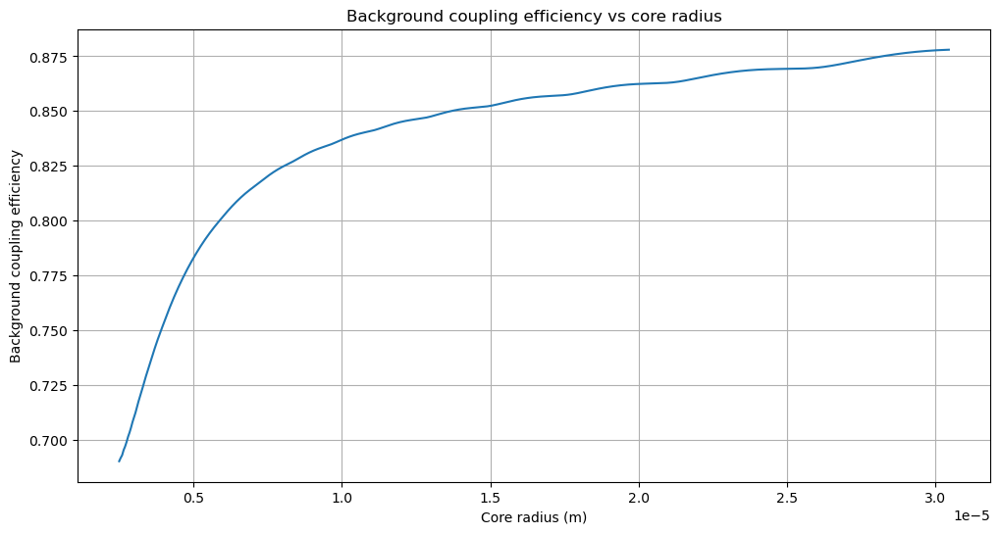

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(core_radius_arr, eta_background_list)
plt.xlabel('Core radius (m)')
plt.ylabel('Background coupling efficiency')
plt.title('Background coupling efficiency vs core radius')
plt.grid(True)
plt.show()

In [ ]:
relative_snr_array = eta_best_arr / np.sqrt(eta_background_list * background_array)
relative_snr_array

array([81.90457381, 78.26818337, 70.75653643, 67.66359864, 64.95740765,
       59.47492609, 57.36517931, 55.33829306, 51.2735082 , 49.65355232,
       48.1944759 , 45.4432946 , 43.73704141, 42.61473637, 41.54368543,
       40.20804719, 38.2303026 , 37.34544144, 36.560388  , 35.80033416,
       34.99553854, 33.57930527, 32.72851999, 32.10765368, 31.55008008,
       31.02563168, 30.52114593, 30.02748041, 29.53420573, 29.02102279,
       28.40898813, 27.69398587, 27.21709593, 26.81614991, 26.45096264,
       26.10908078, 25.78484478, 25.47517627, 25.17812499, 24.89238107,
       24.61697551, 24.35116675, 24.09434919, 23.84602218, 23.60572878,
       23.37307869, 23.14770417, 22.92926091, 22.71744769, 22.51195629,
       22.31252963, 22.11891868, 21.93089465, 21.74828306, 21.5708944 ,
       21.39862043, 21.23137769, 21.06909041, 20.91180525, 20.75958878,
       20.61261368, 20.47118519, 20.3357836 , 20.20719664, 20.08661418,
       19.97600852, 19.8785015 , 19.79841998, 19.73732485, 19.68

Text(0.5, 1.0, 'Magnification vs Core Radius')

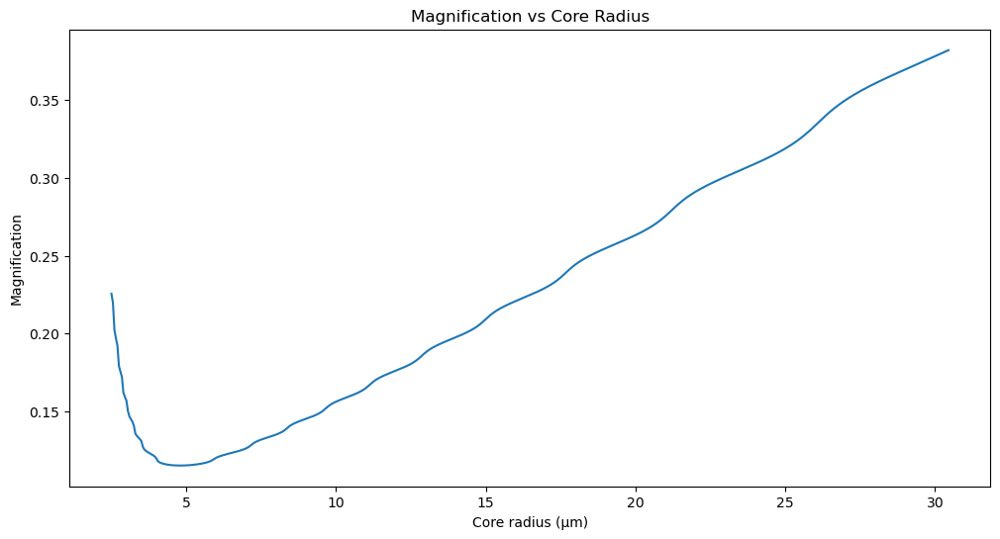

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(core_radius_arr * 1e6, Magnification_list)
plt.xlabel('Core radius (µm)')
plt.ylabel('Magnification')
plt.title('Magnification vs Core Radius')

Text(0.5, 1.0, 'Signal vs Core Radius')

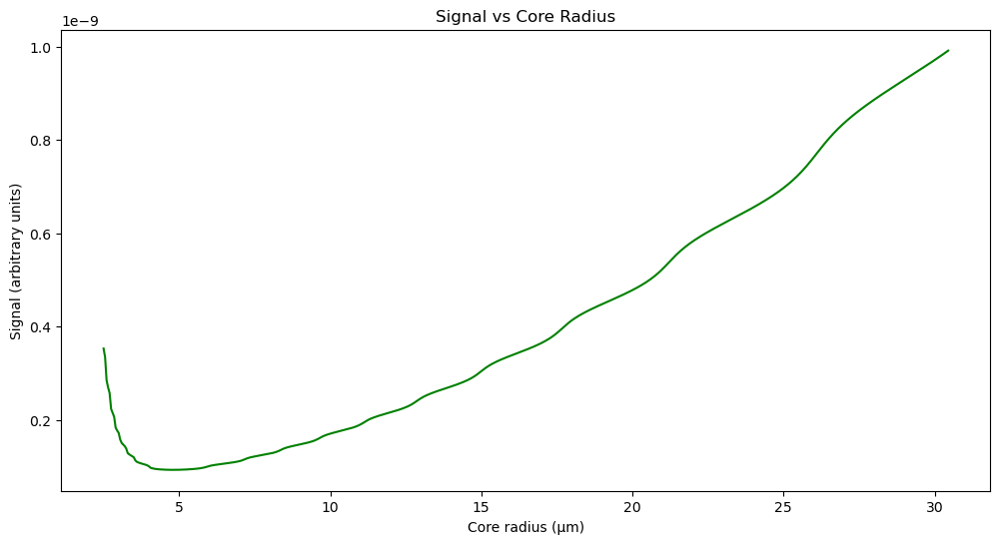

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(core_radius_arr * 1e6, signal_array, label='Signal', color='green')
plt.xlabel('Core radius (µm)')
plt.ylabel('Signal (arbitrary units)')
plt.title('Signal vs Core Radius')

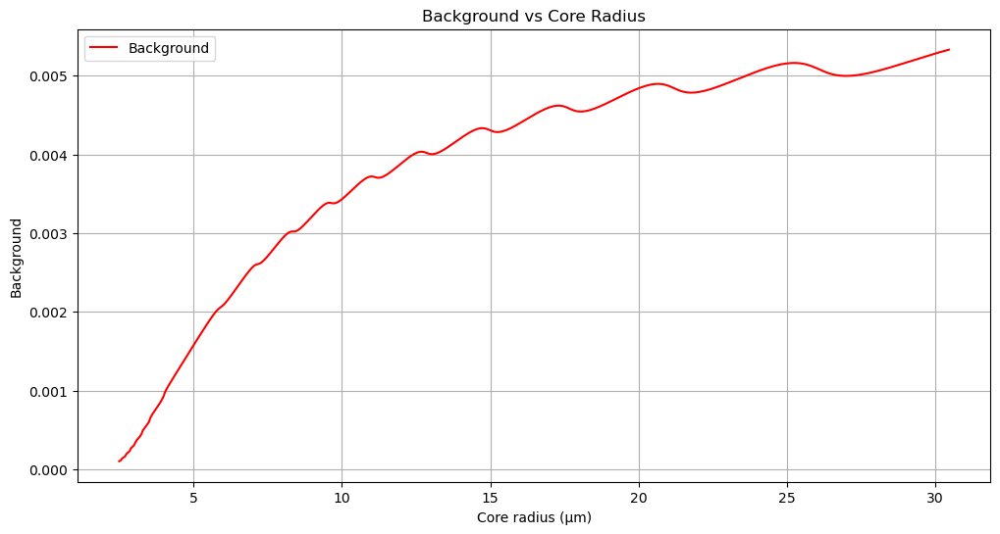

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(core_radius_arr * 1e6, background_array, label='Background', color='red')
plt.xlabel('Core radius (µm)')
plt.ylabel('Background')
plt.title('Background vs Core Radius')
plt.grid(True)
plt.legend()
plt.show()

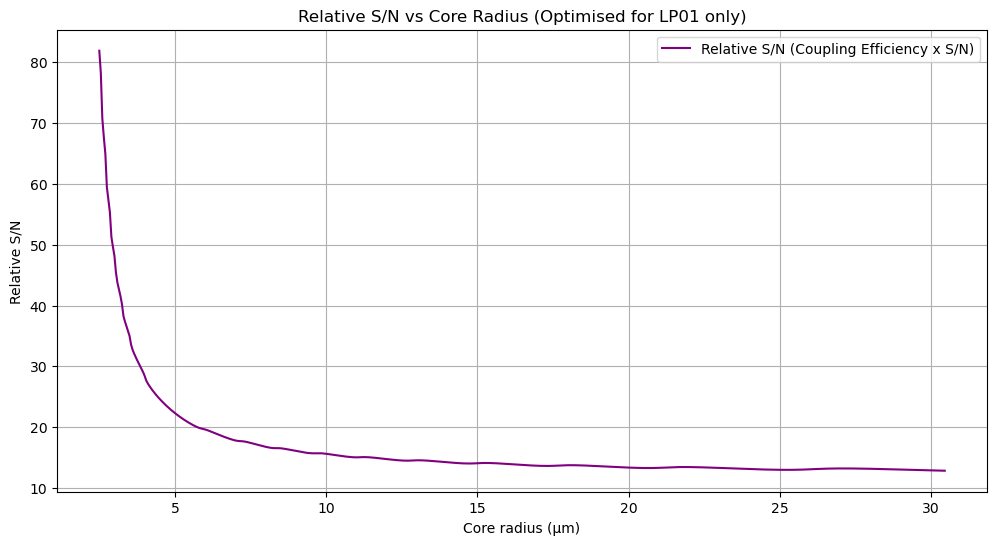

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(core_radius_arr * 1e6, relative_snr_array, label='Relative S/N (Coupling Efficiency x S/N)', color='purple')
# plt.plot(core_radius_arr * 1e6, snr_array, label='S/N (No Coupling Efficiency)', color='orange')
plt.xlabel('Core radius (µm)')
plt.ylabel('Relative S/N')
plt.title('Relative S/N vs Core Radius (Optimised for LP01 only)')
plt.grid(True)
plt.legend()
plt.show()

# Test

In [ ]:
import numpy as np
from scipy.special import jn_zeros

def cutoff(l, m): 
    """
    Utility function which returns the normalised frequency (V) at cutoff for
    a given mode l,m.

    Arguments:

    l: Azimuthal order of the LP mode, integer >=0
    m: Radial order of the LP mode, integer >=1

    Return value:

    Vc: Normalised frequency at cutoff for the given mode, equals to the last zero of J_{l-1} for l>=1, and the last zero of J_{m-1} for l=0.
    """
    
    if l >= 1:
        return jn_zeros(l - 1, m)[-1]
    elif l == 0:
        if m == 1:
            return 0.0
        else:
            return jn_zeros(1, m - 1)[-1]
    else:
        raise ValueError("l must be >= 0")

In [ ]:
def modes(V, l_max=10, m_max=10, v_margin=2e-3):
    """
    For each value of l, calculate the allowed values of m (if any). 

    Arguments:
    V: Normalised frequency of the fibre
    l_max: Maximum azimuthal order to consider
    m_max: Maximum radial order to consider
    v_margin: Margin to consider for mode cutoff, to account for numerical precision issues. 

    Return value:
    modelist: A list of [l, m, Vc] for each mode that is supported by the fibre, where Vc is the cutoff V-number for that mode. 
    """
    mode_list = []
    for l in range(l_max + 1):
        for m in range(1, m_max + 1):
            vc = cutoff(l, m)
            if V > vc + v_margin:
                mode_list.append([l, m, vc])
    return mode_list

In [ ]:
from scipy.special import jv, kv

def fu(u, V, l):
    """
    Function whose zeros determine the transverse propagation contants
    u and w.

    Arguments:

    u: Trial value of the tranverse propagation constant u, float >= 0
    V:  Normalised frequency, float >= 0
    l:  Azimuthal order of the LP mode, integer >= 0

    Return value:
    f: Value of the function at the given u, V, l. The roots of this function correspond to the allowed modes of the fibre, as 
    they determine the relationship between the transverse propagation
    """

    w = np.sqrt(V**2 - u**2)
    if l > 0:
        return u * jv(l - 1, u) / jv(l, u) + w * kv(l - 1, w) / kv(l, w)
    elif l == 0:
        return u * jv(1, u) / jv(0, u) - w * kv(1, w) / kv(0, w)
    else:
        raise ValueError("l must be >= 0")

In [ ]:
from scipy.optimize import brentq
import numpy as np

def uw(l, m, V, eps=1e-8, n_scan=2000):
    """
    Calculates the two transverse propagation constants u & w for a given
    normalised frequency and l,m.

    Arguments:

    V: Normalised frequency, float >= cutoff(l,m)
    l: Azimuthal order of the LP mode, integer >= 0
    m: Radial order of the LP mode, integer >= 1
    eps: Margin to consider for cutoff, to avoid numerical issues when V is very close to cutoff
    n_scan: Number of points to scan for a sign change in the fu function, which determines the roots corresponding to the allowed modes.

    Returned values:

    u: Transverse propagation constant for the core, float
    w: Transverse propagation constant for the cladding, float
    """
    
    vc_low = cutoff(l, m)

    if V <= vc_low:
        raise ValueError(f"V={V:.6f} is below cutoff for mode ({l},{m})")

    vc_high = cutoff(l + 1, m)

    lower = vc_low * (1 + eps)
    upper = min(vc_high * (1 - eps), V * (1 - eps))

    # Special case for LP01
    if l == 0 and m == 1:
        lower = eps

    if not (lower < upper):
        raise ValueError(
            f"Invalid bracket for mode ({l},{m}): lower={lower}, upper={upper}, V={V}"
        )

    f = lambda x: fu(x, V, l)

    # Scan for an actual sign change inside the interval
    u_scan = np.linspace(lower, upper, n_scan)
    f_scan = np.array([f(u) for u in u_scan])

    bracket = None
    for i in range(len(u_scan) - 1):
        f1 = f_scan[i]
        f2 = f_scan[i + 1]

        if not (np.isfinite(f1) and np.isfinite(f2)):
            continue

        if f1 * f2 < 0:
            bracket = (u_scan[i], u_scan[i + 1])
            break

    if bracket is None:
        raise ValueError(
            f"No sign-change bracket found for mode ({l},{m}) at V={V:.6f}. "
            f"Initial interval was [{lower:.6f}, {upper:.6f}]"
        )

    u = brentq(f, bracket[0], bracket[1])
    w = np.sqrt(V**2 - u**2)
    return u, w

In [ ]:
def lp_radial_field(r, a, l, u, w):
    """
    1D function that evaluates the radial part of the electric field for an LP mode at a given radius r, normalised by the core radius a, 
    and given the azimuthal order l and transverse propagation constants u and w. 

    Returns the electric field of the fibre LP mode for a azimuthally symmetric mode.
    """
    rho = r / a
    E = np.zeros_like(rho)

    core = rho <= 1
    cladding = rho > 1

    E[core] = jv(l, u * rho[core]) / jv(l, u)
    E[cladding] = kv(l, w * rho[cladding]) / kv(l, w)

    return E

In [ ]:
def total_eff_1d(a, NA, wave, F, alpha, r, E_S=1.0, az_sym=True):
    """
    Calculates the total coupling efficiency included all symmetric LP modes
    above their cutoff.

    In the original function of Horton & Bland-Hawthorn 2007, if the image is azimuthally symmetric then the optional parameter
    az_sym can be set to True to speed up the calculationby only
    considering the l=0 modes. 
    """

    V = 2 * np.pi * a * NA / wave
    allmodes = modes(V)

    if az_sym:
        allmodes = [mode for mode in allmodes if mode[0] == 0]

    E_image, I_image = diffraction_limited_E_field_at_fibre(r, wave, F, alpha=alpha, E_S=E_S)

    total = 0.0
    mode_results = []

    for mode in allmodes:
        l, m, vc = mode
        try:
            u, w = uw(l, m, V)
        except ValueError:
            continue

        E_mode = lp_radial_field(r, a, l, u, w)
        eta, num, den = coupling_efficiency_1d(E_image, E_mode, r)
        total += eta

        mode_results.append({
            "l": l,
            "m": m,
            "cutoff": vc,
            "u": u,
            "w": w,
            "eta": eta
        })

    return total, mode_results

In [ ]:
from scipy.optimize import fminbound

def best_eff_1d(a, NA, wave, alpha, r, lower=1, upper=30):
    """
    Optimises the total coupling efficiency over F ratio and
    returns the optimal F ratio and the resulting coupling efficiency

    Objectives:
    lower: lower bound for the focal ratio search, default is 1
    upper: upper bound for the focal ratio search, default is 30

    """

    def objective(F):
        total, _ = total_eff_1d(a, NA, wave, F, alpha, r, az_sym=True)
        return 1 - total

    F_opt = fminbound(objective, lower, upper)
    eta_total_opt, mode_results = total_eff_1d(a, NA, wave, F_opt, alpha, r, az_sym=True)

    return F_opt, eta_total_opt, mode_results

In [ ]:
def Fvsd_1d(A, NA, wave, alpha, r): 
    """
    Fvsd stands for "F vs d", where F is the optimal focal ratio that maximises coupling efficiency, and d is the core radius of the fibre. 

    A: array of core radius values to test
    NA: numerical aperture of the fibre
    wave: wavelength of the light in meters
    alpha: central obstruction ratio
    r: radial coordinate array for evaluating the electric field and coupling efficiency
    """

    lower = 1
    upper = 30
    data = []

    n_total = len(A)
    checkpoints = {max(1, int(np.ceil(n_total * p / 10))) for p in range(1, 11)}

    for i, a in enumerate(A, start=1):
        F_opt, eta_total_opt, mode_results = best_eff_1d(
            a, NA, wave, alpha, r, lower=lower, upper=upper
        )

        data.append({
            "a": a,
            "F_opt": F_opt,
            "eta_total_opt": eta_total_opt,
            "mode_results": mode_results
        })

        lower = F_opt * 0.7
        upper = F_opt * 1.05

        if i in checkpoints:
            percent = int(round(100 * i / n_total))
            print(f"{percent}% complete ({i}/{n_total})")

    return data

In [ ]:
data = Fvsd_1d(core_radius_range_test, NA, lam0, alpha=0.0, r=r)

10% complete (56/560)
20% complete (112/560)
30% complete (168/560)
40% complete (224/560)
50% complete (280/560)
60% complete (336/560)
70% complete (392/560)
80% complete (448/560)
90% complete (504/560)
100% complete (560/560)


In [ ]:
a_arr = np.array([row["a"] for row in data])
Fopt_arr = np.array([row["F_opt"] for row in data])
eta_arr = np.array([row["eta_total_opt"] for row in data])

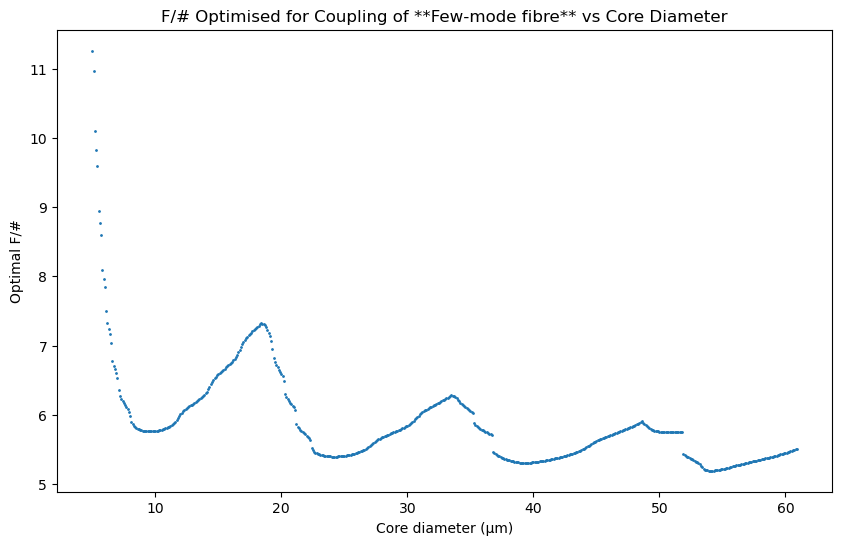

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(2 * a_arr * 1e6, Fopt_arr, s=1)
plt.xlabel("Core diameter (µm)")
plt.ylabel("Optimal F/#")
plt.title("F/# Optimised for Coupling of **Few-mode fibre** vs Core Diameter")
plt.show()


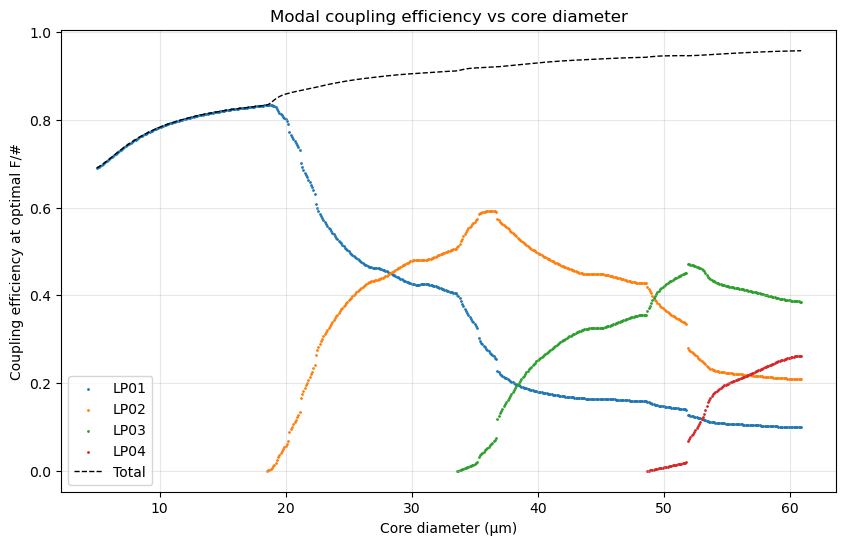

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Core radius array
a_arr = np.array([row["a"] for row in data])          # in meters
a_um = a_arr * 1e6                                    # convert to microns

# Prepare arrays for LP01, LP02, LP03 efficiencies
eta_LP01 = np.full(len(data), np.nan)
eta_LP02 = np.full(len(data), np.nan)
eta_LP03 = np.full(len(data), np.nan)
eta_LP04 = np.full(len(data), np.nan)
eta_tot = np.array([row["eta_total_opt"] for row in data])

# Extract modal efficiencies from mode_results
for i, row in enumerate(data):
    for mode in row["mode_results"]:
        l = mode["l"]
        m = mode["m"]
        eta = mode["eta"]

        if l == 0 and m == 1:
            eta_LP01[i] = eta
        elif l == 0 and m == 2:
            eta_LP02[i] = eta
        elif l == 0 and m == 3:
            eta_LP03[i] = eta
        elif l == 0 and m == 4:
            eta_LP04[i] = eta

# Plot
plt.figure(figsize=(10, 6))
plt.scatter(2* a_um, eta_LP01, s=1, label='LP01')
plt.scatter(2* a_um, eta_LP02, s=1, label='LP02')
plt.scatter(2* a_um, eta_LP03, s=1, label='LP03')
plt.scatter(2* a_um, eta_LP04, s=1, label='LP04')
plt.plot(2* a_um, eta_tot, linestyle='--', label='Total', color='black', linewidth=1)
plt.xlabel("Core diameter (µm)")
plt.ylabel("Coupling efficiency at optimal F/#")
plt.title("Modal coupling efficiency vs core diameter")
# plt.ylim(0.68, 0.9)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Core radius array
a_arr = np.array([row["a"] for row in data])          # in meters
a_um = a_arr * 1e6                                    # convert to microns
F_ratio = np.array([row["F_opt"] for row in data])

# Prepare arrays for LP01, LP02, LP03 efficiencies
eta_LP01 = np.full(len(data), np.nan)
eta_LP02 = np.full(len(data), np.nan)
eta_LP03 = np.full(len(data), np.nan)

# Extract modal efficiencies from mode_results
for i, row in enumerate(data):
    for mode in row["mode_results"]:
        l = mode["l"]
        m = mode["m"]
        eta = mode["eta"]

        if l == 0 and m == 1:
            eta_LP01[i] = eta
        elif l == 0 and m == 2:
            eta_LP02[i] = eta
        elif l == 0 and m == 3:
            eta_LP03[i] = eta



In [ ]:
F_ratio.shape

(560,)

In [ ]:
def eta_total_vs_F(a, NA, wave, alpha, r, F_grid):
    eta_grid = []

    for F in F_grid:
        eta_total, mode_results = total_eff_1d(a, NA, wave, F, alpha, r, az_sym=True)
        eta_grid.append(eta_total)

    return np.array(eta_grid)

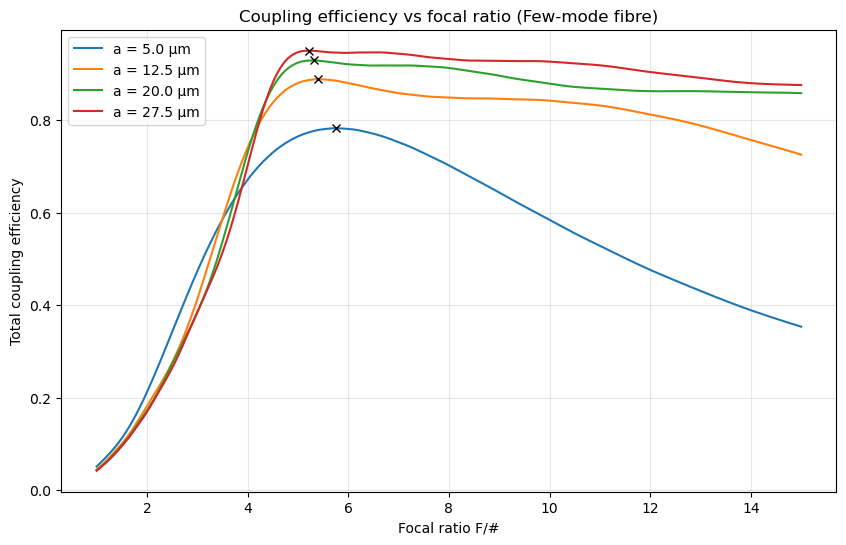

In [ ]:
target_radii_um = [5, 12.5, 20, 27.5]

plt.figure(figsize=(10, 6))

for target_um in target_radii_um:
    a_target = target_um * 1e-6

    # Use the closest radius available in your sampled array
    idx = np.argmin(np.abs(a_arr - a_target))
    a_use = a_arr[idx]

    # Use a focal-ratio range
    F_grid = np.linspace(1, 15, 200)
    eta_grid = eta_total_vs_F(a_use, NA, lam0, alpha=0.0, r=r, F_grid=F_grid)

    plt.plot(F_grid, eta_grid, label=f"a = {a_use*1e6:.1f} µm")

    F_opt = data[idx]["F_opt"]
    eta_opt = data[idx]["eta_total_opt"]
    plt.plot(F_opt, eta_opt, "x", color="k")

plt.xlabel("Focal ratio F/#")
plt.ylabel("Total coupling efficiency")
plt.title("Coupling efficiency vs focal ratio (Few-mode fibre)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
    

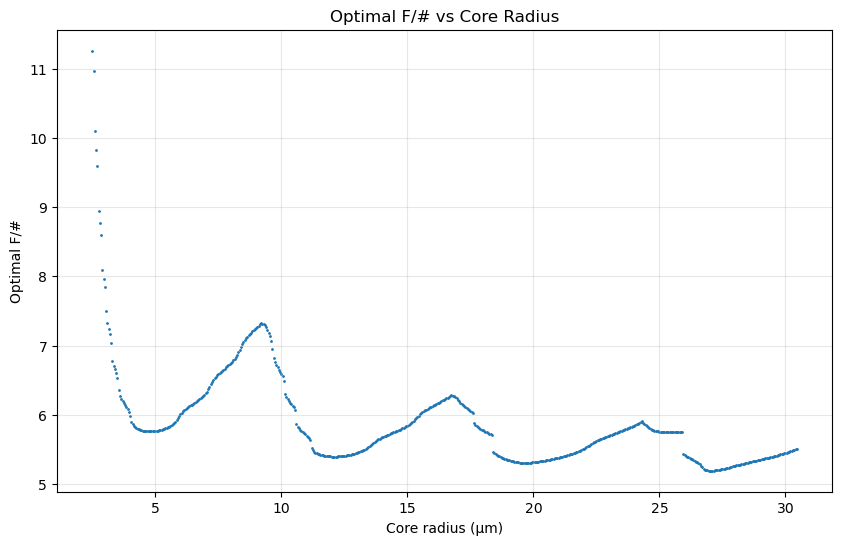

In [ ]:
# Plot optimal F/# vs core radius
plt.figure(figsize=(10,6))
plt.scatter(a_arr * 1e6, F_ratio, s=1)
plt.xlabel("Core radius (µm)")
plt.ylabel("Optimal F/#")
plt.title("Optimal F/# vs Core Radius")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
from scipy import optimize

def eff_1d(l, m, a, NA, wave, F, alpha, r):
    V = 2 * np.pi * a * NA / wave
    u, w = uw(l, m, V)

    E_mode = lp_radial_field(r, a, l, u, w)
    E_image, _ = diffraction_limited_E_field_at_fibre(r, wave, F, alpha=alpha, E_S=1.0)

    eta, numerator, denominator = coupling_efficiency_1d(E_image, E_mode, r)
    return eta, numerator, denominator


def best_eff_LP01(a, NA, wave, alpha, r, lower=1, upper=15):
    F_opt = optimize.fminbound(
        lambda F: 1 - eff_1d(0, 1, a, NA, wave, F, alpha, r)[0],
        lower,
        upper
    )

    eta_best, numerator, denominator = eff_1d(0, 1, a, NA, wave, F_opt, alpha, r)

    return {
        "a": a,
        "F_opt": F_opt,
        "eta_best": eta_best,
        "numerator": numerator,
        "denominator": denominator
    }


def Fvsd_LP01(A, NA, wave, alpha, r):
    lower = 1
    upper = 15
    data = []

    for a in A:
        row = best_eff_LP01(a, NA, wave, alpha, r, lower=lower, upper=upper)
        data.append(row)

        lower = row["F_opt"] * 0.7
        upper = row["F_opt"] * 1.05

    return data

In [ ]:
def eta_vs_F_LP01(a, NA, wave, alpha, F_grid, pupil=False):
    eta_grid = np.array([
        eff_1d(0, 1, a, NA, wave, F, alpha, pupil)[0]
        for F in F_grid
    ])
    return eta_grid

In [ ]:
data_lp01 = Fvsd_LP01(core_radius_range_test, NA, lam0, alpha=0.0, r=r)

In [ ]:
F_opt_arr.shape

(560,)

In [ ]:
a_arr

array([2.500e-06, 2.550e-06, 2.600e-06, 2.650e-06, 2.700e-06, 2.750e-06,
       2.800e-06, 2.850e-06, 2.900e-06, 2.950e-06, 3.000e-06, 3.050e-06,
       3.100e-06, 3.150e-06, 3.200e-06, 3.250e-06, 3.300e-06, 3.350e-06,
       3.400e-06, 3.450e-06, 3.500e-06, 3.550e-06, 3.600e-06, 3.650e-06,
       3.700e-06, 3.750e-06, 3.800e-06, 3.850e-06, 3.900e-06, 3.950e-06,
       4.000e-06, 4.050e-06, 4.100e-06, 4.150e-06, 4.200e-06, 4.250e-06,
       4.300e-06, 4.350e-06, 4.400e-06, 4.450e-06, 4.500e-06, 4.550e-06,
       4.600e-06, 4.650e-06, 4.700e-06, 4.750e-06, 4.800e-06, 4.850e-06,
       4.900e-06, 4.950e-06, 5.000e-06, 5.050e-06, 5.100e-06, 5.150e-06,
       5.200e-06, 5.250e-06, 5.300e-06, 5.350e-06, 5.400e-06, 5.450e-06,
       5.500e-06, 5.550e-06, 5.600e-06, 5.650e-06, 5.700e-06, 5.750e-06,
       5.800e-06, 5.850e-06, 5.900e-06, 5.950e-06, 6.000e-06, 6.050e-06,
       6.100e-06, 6.150e-06, 6.200e-06, 6.250e-06, 6.300e-06, 6.350e-06,
       6.400e-06, 6.450e-06, 6.500e-06, 6.550e-06, 

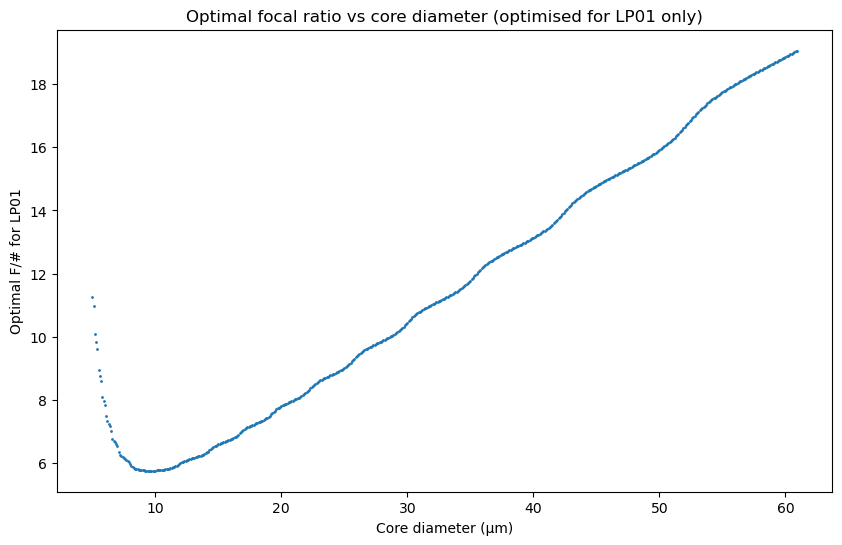

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(2* a_arr * 1e6, F_opt_arr, s=1)
plt.xlabel("Core diameter (µm)")
plt.ylabel("Optimal F/# for LP01")
plt.title("Optimal focal ratio vs core diameter (optimised for LP01 only)")
# plt.grid(True, alpha=0.3)
plt.show()

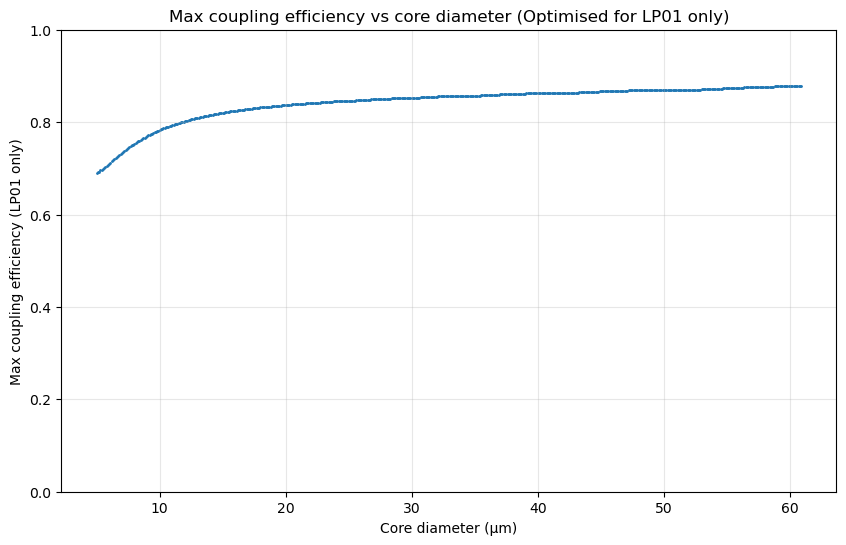

In [ ]:
# Plot efficiency of LP01 only vs core radius
eta_lp01_arr = np.array([row["eta_best"] for row in data_lp01])
plt.figure(figsize=(10, 6))
plt.scatter(2* a_arr * 1e6, eta_lp01_arr, s=1)
plt.xlabel("Core diameter (µm)")
plt.ylabel("Max coupling efficiency (LP01 only)")
plt.title("Max coupling efficiency vs core diameter (Optimised for LP01 only)")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.show()

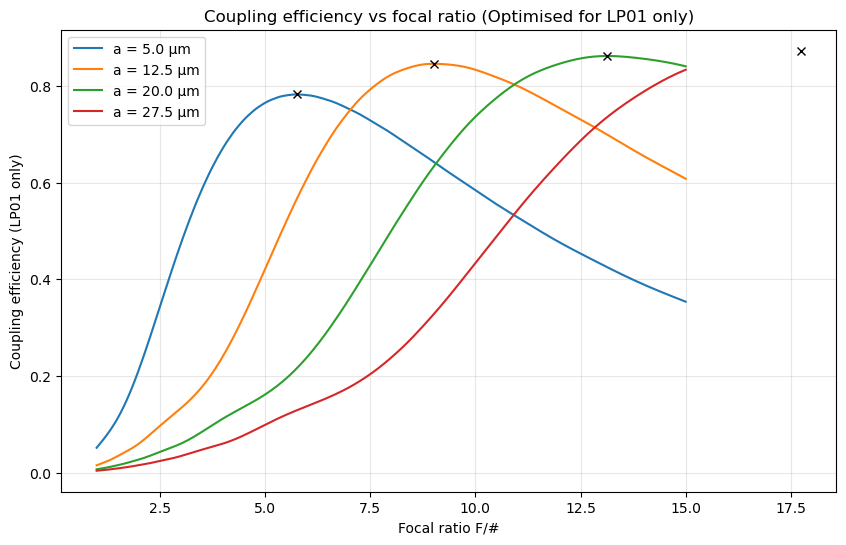

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def eta_vs_F_LP01(a, NA, wave, alpha, F_grid, r):
    eta_grid = np.array([
        eff_1d(0, 1, a, NA, wave, F, alpha, r)[0]
        for F in F_grid
    ])
    return eta_grid

a_arr = np.array([row["a"] for row in data_lp01])

target_radii_um = [5, 12.5, 20, 27.5]

plt.figure(figsize=(10, 6))

for target_um in target_radii_um:
    a_target = target_um * 1e-6
    idx = np.argmin(np.abs(a_arr - a_target))
    a_use = a_arr[idx]

    F_grid = np.linspace(1, 15, 200)
    eta_grid = eta_vs_F_LP01(a_use, NA, lam0, alpha=0.0, F_grid=F_grid, r=r)

    plt.plot(F_grid, eta_grid, label=f"a = {a_use*1e6:.1f} µm")

    F_opt = data_lp01[idx]["F_opt"]
    eta_opt = data_lp01[idx]["eta_best"]
    plt.plot(F_opt, eta_opt, "x", color="k")

plt.xlabel("Focal ratio F/#")
plt.ylabel("Coupling efficiency (LP01 only)")
plt.title("Coupling efficiency vs focal ratio (Optimised for LP01 only)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()